# NBA shot prediction: data cleaning and exploratory analysis

**Research question:** Can we predict whether an NBA player makes a field-goal attempt using
shot location, distance, game situation, and offensive and defensive skill?

This notebook combines the four supplied archives, audits and cleans the records, explores
shooting patterns, and creates historical features for a later prediction model.
The unit of analysis is **one recorded field-goal attempt**. The binary target is
`shot_made_flag` (1 = made, 0 = missed). Free throws and possessions without a recorded
field-goal attempt are outside this dataset.

We define prediction time as **shot release**, when location, shot value, and the game clock
are known. Player history measures offensive shooting skill; opponents' historical FG%
allowed provides a limited team-level defensive proxy. Individual defenders, contests,
lineups, score margin, and shot-clock time are not present.

**Run:** select a Python environment with `requirements.txt` installed, then **Restart Kernel
and Run All**. Keep this notebook beside the four original `.tar.xz` files. Inputs remain
unchanged; generated data, tables, and figures are overwritten on rerun. No network access is
needed after installing dependencies. No model is fitted in this basic EDA notebook.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import re
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not list(ROOT.glob('shotdetail*.tar.xz')):
    raise FileNotFoundError('Run the notebook from the folder containing the four shotdetail archives.')
DATA_DIR = ROOT / 'data' / 'processed'
REPORT_DIR = ROOT / 'reports'
FIGURE_DIR = ROOT / 'figures'
for directory in (DATA_DIR, REPORT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False,
                     'axes.spines.right': False})

def save_show(fig, name):
    fig.savefig(FIGURE_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

versions = {p: importlib.metadata.version(p) for p in
            ['pandas', 'numpy', 'matplotlib', 'seaborn', 'pyarrow']}
display(pd.Series(versions, name='version').to_frame())

,version
pandas,3.1.0
numpy,2.2.3
matplotlib,3.10.8
seaborn,0.13.2
pyarrow,26.0.0


## 1. Load and combine the sources

Read CSV members directly from the archives without extracting files. Read identifiers as
text, keep source filenames and CSV row numbers, and require the same schema before stacking.
The filename year is the **season start year**: `2024` means 2024–25, and `po` means playoffs.
The inventory below reports actual date coverage; we do not assume coverage from the name alone.
SHA-256 hashes identify exactly which local inputs were analyzed. The original publisher and
collection process were not supplied or independently verified.

In [2]:
parts, inventory = [], []
expected_columns = None
for archive in sorted(ROOT.glob('shotdetail*.tar.xz')):
    match = re.fullmatch(r'shotdetail_(po_)?(\d{4})(?: \(\d+\))?\.tar\.xz', archive.name)
    if not match:
        raise ValueError(f'Unrecognized source filename: {archive.name}')
    season_start = int(match.group(2))
    season = f'{season_start}-{str(season_start + 1)[-2:]}'
    season_type = 'Playoffs' if match.group(1) else 'Regular season'
    with tarfile.open(archive, 'r:xz') as bundle:
        members = [m for m in bundle.getmembers() if m.isfile() and m.name.endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'Expected one CSV in {archive.name}, found {len(members)}')
        part = pd.read_csv(bundle.extractfile(members[0]), dtype='string')
    part.columns = part.columns.str.lower().str.strip()
    if expected_columns is None:
        expected_columns = part.columns.tolist()
    assert part.columns.tolist() == expected_columns, 'Source schemas differ; review before combining.'
    dates = pd.to_datetime(part['game_date'], format='%Y%m%d', errors='coerce')
    inventory.append({'source_archive': archive.name, 'source_member': members[0].name,
                      'season': season, 'season_type': season_type, 'shots': len(part),
                      'games': part['game_id'].nunique(), 'players': part['player_id'].nunique(),
                      'first_date': dates.min(), 'last_date': dates.max(),
                      'sha256': hashlib.sha256(archive.read_bytes()).hexdigest()})
    part['source_archive'] = archive.name
    part['source_member'] = members[0].name
    part['source_csv_row'] = np.arange(2, len(part) + 2)
    part['season_start'] = season_start
    part['season'] = season
    part['season_type'] = season_type
    parts.append(part)

raw = pd.concat(parts, ignore_index=True)
source_inventory = pd.DataFrame(inventory)
display(source_inventory.drop(columns='sha256'))
print(f'Combined raw table: {len(raw):,} rows × {raw.shape[1]} columns')
display(raw.head(3))
del parts, part

,source_archive,source_member,season,season_type,shots,games,players,first_date,last_date
0,shotdetail_2024.tar.xz,shotdetail_2024.csv,2024-25,Regular season,219527,1230,566,2024-10-22,2025-04-13
1,shotdetail_2025.tar.xz,shotdetail_2025.csv,2025-26,Regular season,219160,1230,582,2025-10-21,2026-04-12
2,shotdetail_po_2024.tar.xz,shotdetail_po_2024.csv,2024-25,Playoffs,14377,84,217,2025-04-19,2025-06-22
3,shotdetail_po_2025 (1).tar.xz,shotdetail_po_2025.csv,2025-26,Playoffs,14473,85,221,2026-04-18,2026-06-13


Combined raw table: 467,537 rows × 30 columns


,grid_type,game_id,game_event_id,player_id,player_name,team_id,team_name,period,minutes_remaining,seconds_remaining,event_type,action_type,shot_type,shot_zone_basic,shot_zone_area,shot_zone_range,shot_distance,loc_x,loc_y,shot_attempted_flag,shot_made_flag,game_date,htm,vtm,source_archive,source_member,source_csv_row,season_start,season,season_type
0,Shot Chart Detail,22400001,7,1642258,Zaccharie Risacher,1610612737,Atlanta Hawks,1,11,43,Missed Shot,Jump Shot,3PT Field Goal,Above the Break 3,Left Side Center(LC),24+ ft.,26,-168,205,1,0,20241112,BOS,ATL,shotdetail_2024.tar.xz,shotdetail_2024.csv,2,2024,2024-25,Regular season
1,Shot Chart Detail,22400001,10,1630552,Jalen Johnson,1610612737,Atlanta Hawks,1,11,38,Missed Shot,Driving Floating Bank Jump Shot,2PT Field Goal,Mid-Range,Left Side(L),8-16 ft.,13,-136,-1,1,0,20241112,BOS,ATL,shotdetail_2024.tar.xz,shotdetail_2024.csv,3,2024,2024-25,Regular season
2,Shot Chart Detail,22400001,21,1630552,Jalen Johnson,1610612737,Atlanta Hawks,1,10,50,Made Shot,Jump Shot,3PT Field Goal,Above the Break 3,Right Side Center(RC),24+ ft.,25,157,203,1,1,20241112,BOS,ATL,shotdetail_2024.tar.xz,shotdetail_2024.csv,4,2024,2024-25,Regular season


## 2. Audit, clean, and record decisions

- Standardize column names, trim text, normalize Unicode, parse dates and numeric measurements.
- Keep IDs as identifiers; pad game IDs to 10 digits for consistent future joins.
- Remove only identical repeated shot records. Stop if the same shot key has conflicting data.
- Quarantine records with unusable IDs, labels, dates, shot types, or clocks. Do not fill in outcomes.
- Preserve valid long-distance shots, zero-foot attempts, and unusual but valid coordinates.
- Flag inconsistent shot zones and distance/coordinate relationships for sensitivity analysis.
- Use player IDs for grouping. Preserve original name spellings in `player_name_source` and use
  the latest observed spelling only as a display label, never as a model feature.

Missingness and removal counts are computed below, including zero counts. No statistical
outlier removal or blanket numeric imputation is applied.

In [3]:
missing_before = raw[expected_columns].isna().sum().rename('missing_before')
shots = raw.copy()
for column in shots.select_dtypes(include=['string', 'object']).columns:
    shots[column] = shots[column].astype('string').str.normalize('NFC').str.strip().replace('', pd.NA)

numeric_columns = ['game_event_id', 'period', 'minutes_remaining', 'seconds_remaining',
                   'shot_distance', 'loc_x', 'loc_y', 'shot_attempted_flag', 'shot_made_flag']
coercion_counts = {}
for column in numeric_columns:
    parsed = pd.to_numeric(shots[column], errors='coerce')
    coercion_counts[column] = int((parsed.isna() & shots[column].notna()).sum())
    shots[column] = parsed
parsed_dates = pd.to_datetime(shots['game_date'], format='%Y%m%d', errors='coerce')
coercion_counts['game_date'] = int((parsed_dates.isna() & shots['game_date'].notna()).sum())
shots['game_date'] = parsed_dates
shots['game_id'] = shots['game_id'].str.zfill(10)

# Provenance does not make two otherwise identical shot records different.
dedup_columns = expected_columns + ['season', 'season_type']
duplicate_count = int(shots.duplicated(dedup_columns).sum())
shots = shots.drop_duplicates(dedup_columns).copy()
shot_key = ['game_id', 'game_event_id']
conflicting = shots.duplicated(shot_key, keep=False)
if conflicting.any():
    shots.loc[conflicting].to_csv(REPORT_DIR / 'conflicting_shot_keys.csv', index=False)
    raise ValueError('Conflicting shot keys found. Review reports/conflicting_shot_keys.csv.')

period_seconds = shots['minutes_remaining'] * 60 + shots['seconds_remaining']
period_length = pd.Series(np.where(shots['period'].le(4).fillna(False), 720, 300), index=shots.index)
invalid = pd.DataFrame({
    'invalid_identifier': (~shots['game_id'].str.fullmatch(r'\d{10}', na=False)
                          | ~shots['player_id'].str.fullmatch(r'\d+', na=False)
                          | ~shots['team_id'].str.fullmatch(r'\d+', na=False)
                          | shots['game_event_id'].isna() | shots['game_event_id'].lt(0)
                          | shots['game_event_id'].mod(1).ne(0)),
    'invalid_target_or_attempt': (~shots['shot_made_flag'].isin([0, 1])
                                 | ~shots['shot_attempted_flag'].eq(1)),
    'invalid_date': shots['game_date'].isna(),
    'invalid_clock': (shots[['period', 'minutes_remaining', 'seconds_remaining']].isna().any(axis=1)
                      | shots['period'].lt(1) | shots['period'].mod(1).ne(0)
                      | shots['minutes_remaining'].mod(1).ne(0)
                      | shots['seconds_remaining'].mod(1).ne(0)
                      | ~shots['seconds_remaining'].between(0, 59)
                      | period_seconds.lt(0) | period_seconds.gt(period_length)),
    'invalid_shot_type': ~shots['shot_type'].isin(['2PT Field Goal', '3PT Field Goal']),
}).fillna(True)
quarantine = shots.loc[invalid.any(axis=1)].copy()
quarantine['rejection_reason'] = pd.Series(
    [', '.join(row.index[row]) for _, row in invalid.loc[invalid.any(axis=1)].iterrows()],
    index=quarantine.index, dtype='string')
shots = shots.loc[~invalid.any(axis=1)].copy()
for column in ['game_event_id', 'period', 'minutes_remaining', 'seconds_remaining',
               'shot_attempted_flag', 'shot_made_flag']:
    shots[column] = shots[column].astype('Int64')

shots['player_name_source'] = shots['player_name']
name_variants = (shots.groupby('player_id')['player_name_source']
                 .agg(lambda s: ' / '.join(sorted(s.dropna().unique()))).rename('observed_names'))
variant_ids = shots.groupby('player_id')['player_name_source'].nunique()
name_variants = name_variants.loc[variant_ids.gt(1)].reset_index()
display_names = (shots.sort_values(['game_date', 'game_id', 'game_event_id'])
                 .drop_duplicates('player_id', keep='last').set_index('player_id')['player_name'])
shots['player_name'] = shots['player_id'].map(display_names)
shots['action_type'] = shots['action_type'].str.casefold()

shots['x_ft'] = shots['loc_x'].astype(float) / 10
shots['y_ft'] = shots['loc_y'].astype(float) / 10
shots['coordinate_distance_ft'] = np.hypot(shots['x_ft'], shots['y_ft'])
shots['distance_coordinate_mismatch'] = (
    shots['shot_distance'].isna() | shots['coordinate_distance_ft'].isna()
    | np.floor(shots['coordinate_distance_ft'] + 1e-9).ne(shots['shot_distance'])).fillna(True)
three_zones = ['Above the Break 3', 'Left Corner 3', 'Right Corner 3', 'Backcourt']
two_zones = ['Restricted Area', 'In The Paint (Non-RA)', 'Mid-Range']
shots['shot_type_zone_mismatch'] = (
    (shots['shot_type'].eq('2PT Field Goal') & shots['shot_zone_basic'].isin(three_zones))
    | (shots['shot_type'].eq('3PT Field Goal') & shots['shot_zone_basic'].isin(two_zones)))
shots['event_target_mismatch'] = ~shots['event_type'].eq(
    shots['shot_made_flag'].map({1: 'Made Shot', 0: 'Missed Shot'}))
shots['season_date_mismatch'] = ~(
    shots['game_date'].ge(pd.to_datetime(shots['season_start'].astype(str) + '-07-01'))
    & shots['game_date'].lt(pd.to_datetime((shots['season_start'] + 1).astype(str) + '-07-01')))
shots['measurement_review_flag'] = (shots[['shot_distance', 'loc_x', 'loc_y']].isna().any(axis=1)
                                    | shots['shot_distance'].lt(0)).fillna(True)

quality_flags = ['shot_type_zone_mismatch', 'distance_coordinate_mismatch',
                 'event_target_mismatch', 'season_date_mismatch', 'measurement_review_flag']
cleaning_log = pd.DataFrame([
    {'step': 'Raw input rows', 'rows': len(raw)},
    {'step': 'Identical duplicate rows removed', 'rows': duplicate_count},
    {'step': 'Unusable records quarantined', 'rows': len(quarantine)},
    {'step': 'Clean rows retained', 'rows': len(shots)},
])
quality_summary = shots[quality_flags].sum().rename('flagged_rows').to_frame()
missingness = pd.concat([missing_before, shots[expected_columns].isna().sum().rename('missing_after')], axis=1)
missingness['missing_after_pct'] = missingness['missing_after'] / len(shots)
display(cleaning_log, quality_summary, name_variants, missingness)
assert len(raw) == duplicate_count + len(quarantine) + len(shots)
assert not shots.duplicated(shot_key).any()
assert shots['shot_made_flag'].isin([0, 1]).all()

,step,rows
0,Raw input rows,467537
1,Identical duplicate rows removed,0
2,Unusable records quarantined,0
3,Clean rows retained,467537


,flagged_rows
shot_type_zone_mismatch,33
distance_coordinate_mismatch,0
event_target_mismatch,0
season_date_mismatch,0
measurement_review_flag,0


,player_id,observed_names
0,1628420,Monte Morris / Monté Morris
1,202685,Jonas Valanciunas / Jonas Valančiūnas
2,203967,Dario Saric / Dario Šarić


,missing_before,missing_after,missing_after_pct
grid_type,0,0,0.000
game_id,0,0,0.000
game_event_id,0,0,0.000
player_id,0,0,0.000
player_name,0,0,0.000
team_id,0,0,0.000
team_name,0,0,0.000
period,0,0,0.000
minutes_remaining,0,0,0.000
seconds_remaining,0,0,0.000


**Interpretation of the audit:** the coordinate scale is checked against the supplied distance:
`floor(sqrt((LOC_X / 10)² + (LOC_Y / 10)²))` should match `SHOT_DISTANCE`.
The check uses a 1e-9-foot tolerance before flooring to avoid falsely flagging exact distances
such as 13 feet represented as 12.999999999999998. This validates conversion to feet empirically
rather than assuming coordinates are already feet.
The 33 shot-type/zone disagreements are retained with a flag because these files alone cannot
resolve which field is correct. Compare analyses with and without these records later.

## 3. Add opponent and game-situation features

Infer team abbreviations from the intersection of home/visitor codes across each team's games.
Then identify the opponent as the other team in each game, checking that every game has exactly
two teams. No external roster lookup or hand-entered abbreviation map is needed.

Game situation includes home/away, period, seconds remaining in the period, elapsed game time,
overtime, and playoffs. Regulation periods are 12 minutes; overtime periods are 5 minutes.
`is_late_fourth` means the final two minutes of the fourth quarter. It is **not a clutch label**,
because score margin is unavailable. The period clock is **not the shot clock**.

In [4]:
team_codes = {}
for team_id, group in shots.groupby('team_id', sort=False):
    matchups = group[['htm', 'vtm']].drop_duplicates()
    candidates = set.intersection(*(set(pair) for pair in matchups.itertuples(index=False, name=None)))
    assert len(candidates) == 1, f'Ambiguous abbreviation for team {team_id}'
    team_codes[team_id] = candidates.pop()
assert len(set(team_codes.values())) == len(team_codes)
shots['team_abbr'] = shots['team_id'].map(team_codes)
assert (shots['team_abbr'].eq(shots['htm']) | shots['team_abbr'].eq(shots['vtm'])).all()
shots['is_home'] = shots['team_abbr'].eq(shots['htm']).astype('int8')
shots['opponent_abbr'] = np.where(shots['is_home'].eq(1), shots['vtm'], shots['htm'])
shots['opponent_team_id'] = shots['opponent_abbr'].map({abbr: tid for tid, abbr in team_codes.items()})
game_teams = shots.groupby('game_id')['team_id'].agg(lambda x: frozenset(x))
assert game_teams.map(len).eq(2).all()
assert shots.groupby('game_id')[['htm', 'vtm', 'game_date']].nunique().eq(1).all().all()
assert shots.groupby('game_id')['opponent_team_id'].agg(lambda x: frozenset(x)).eq(game_teams).all()
assert shots['team_id'].ne(shots['opponent_team_id']).all()
assert shots['opponent_team_id'].notna().all()

shots['seconds_remaining_period'] = shots['minutes_remaining'] * 60 + shots['seconds_remaining']
shots['period_length_seconds'] = np.where(shots['period'].le(4), 720, 300)
seconds_before_period = np.where(shots['period'].le(4), (shots['period'] - 1) * 720,
                                 2880 + (shots['period'] - 5) * 300)
shots['game_seconds_elapsed'] = seconds_before_period + shots['period_length_seconds'] - shots['seconds_remaining_period']
shots['is_overtime'] = shots['period'].gt(4).astype('int8')
shots['is_playoffs'] = shots['season_type'].eq('Playoffs').astype('int8')
shots['is_three_pointer'] = shots['shot_type'].eq('3PT Field Goal').astype('int8')
shots['is_late_fourth'] = (shots['period'].eq(4) & shots['seconds_remaining_period'].le(120)).astype('int8')
shots['is_final_5_seconds_period'] = shots['seconds_remaining_period'].le(5).astype('int8')
shots['distance_band'] = pd.cut(shots['shot_distance'], bins=[0, 4, 8, 16, 24, 30, np.inf],
                               labels=['0–3', '4–7', '8–15', '16–23', '24–29', '30+'], right=False)
shots = shots.sort_values(['game_date', 'game_id', 'game_event_id']).reset_index(drop=True)
print(f'{len(shots):,} shots; {shots.game_id.nunique():,} games; '
      f'{shots.player_id.nunique():,} players; {shots.team_id.nunique()} teams')
display(shots[['game_id', 'game_date', 'player_name', 'team_abbr', 'opponent_abbr',
               'is_home', 'period', 'seconds_remaining_period', 'shot_made_flag']].head())

467,537 shots; 2,629 games; 684 players; 30 teams


,game_id,game_date,player_name,team_abbr,opponent_abbr,is_home,period,seconds_remaining_period,shot_made_flag
0,0022400061,2024-10-22,Jayson Tatum,BOS,NYK,1,1,708,1
1,0022400061,2024-10-22,OG Anunoby,NYK,BOS,0,1,687,1
2,0022400061,2024-10-22,Jayson Tatum,BOS,NYK,1,1,676,0
3,0022400061,2024-10-22,Jalen Brunson,NYK,BOS,0,1,669,1
4,0022400061,2024-10-22,Derrick White,BOS,NYK,1,1,654,1


## 4. Basic EDA: outcome, distance, location, and time

All summaries in this section describe the supplied sample. FG% means makes divided by attempts;
the denominators are shown alongside rates. These are associations, not causal effects or
out-of-sample prediction results. Full-sample summary rates must not become model inputs.

attempts   makes  fg_pct  games  \
season  season_type                                       
2024-25 Playoffs           14377    6543   0.455     84   
        Regular season    219527  102566   0.467   1230   
2025-26 Playoffs           14473    6538   0.452     85   
        Regular season    219160  103227   0.471   1230   

                        three_point_attempt_share  
season  season_type                                
2024-25 Playoffs                            0.411  
        Regular season                      0.421  
2025-26 Playoffs                            0.404  
        Regular season                      0.415

,count,mean,std,min,25%,50%,75%,max
shot_distance,"467,537.000",13.914,10.585,0.000,3.000,13.000,25.000,86.000
x_ft,"467,537.000",-0.252,11.662,-25.000,-5.300,0.000,4.700,25.000
y_ft,"467,537.000",9.646,9.511,-5.200,1.500,5.700,18.400,85.600
period,"467,537.000",2.480,1.129,1.000,1.000,2.000,3.000,6.000
seconds_remaining_period,"467,537.000",352.505,207.376,0.000,173.000,354.000,533.000,720.000


Made shots: 218,874 / 467,537 (46.81%)
A constant majority-class prediction would score 53.19% accuracy on this full sample; this is descriptive, not a validation score.


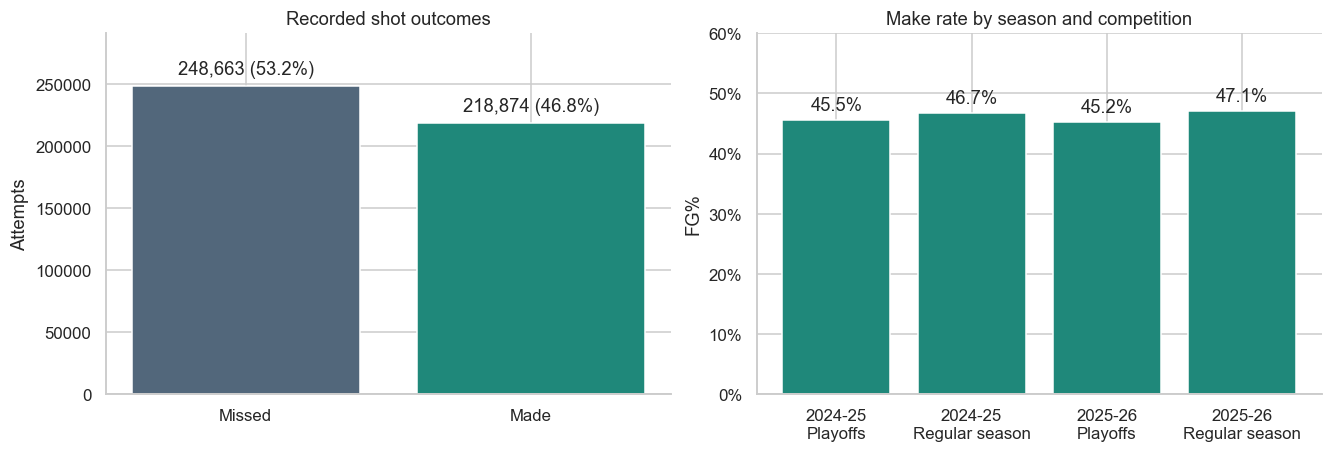

In [5]:
def shot_summary(frame, by):
    result = (frame.groupby(by, observed=True, dropna=False)
              .agg(attempts=('shot_made_flag', 'size'), makes=('shot_made_flag', 'sum')))
    result['fg_pct'] = result['makes'] / result['attempts']
    return result

coverage = shot_summary(shots, ['season', 'season_type'])
coverage['games'] = shots.groupby(['season', 'season_type'])['game_id'].nunique()
coverage['three_point_attempt_share'] = shots.groupby(['season', 'season_type'])['is_three_pointer'].mean()
target_counts = shots['shot_made_flag'].value_counts().reindex([0, 1], fill_value=0)
overall_fg = shots['shot_made_flag'].mean()
display(coverage)
display(shots[['shot_distance', 'x_ft', 'y_ft', 'period', 'seconds_remaining_period']].describe().T)
print(f'Made shots: {shots.shot_made_flag.sum():,} / {len(shots):,} ({overall_fg:.2%})')
print(f'A constant majority-class prediction would score {max(overall_fg, 1-overall_fg):.2%} accuracy '
      'on this full sample; this is descriptive, not a validation score.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
bars = axes[0].bar(['Missed', 'Made'], target_counts, color=['#52677B', '#1F887A'])
axes[0].bar_label(bars, labels=[f'{n:,} ({n/len(shots):.1%})' for n in target_counts], padding=5)
axes[0].set(title='Recorded shot outcomes', ylabel='Attempts', ylim=(0, target_counts.max()*1.17))
labels = [f'{season}\n{kind}' for season, kind in coverage.index]
bars = axes[1].bar(labels, coverage['fg_pct'], color='#1F887A')
axes[1].bar_label(bars, labels=[f'{v:.1%}' for v in coverage['fg_pct']], padding=4)
axes[1].set(title='Make rate by season and competition', ylabel='FG%', ylim=(0, .6))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
save_show(fig, '01_outcomes_and_coverage')

,attempts,makes,fg_pct
shot_zone_basic,,,
Restricted Area,131280,87454,0.666
In The Paint (Non-RA),94227,41785,0.443
Mid-Range,46844,19495,0.416
Left Corner 3,26021,10033,0.386
Right Corner 3,24278,9387,0.387
Above the Break 3,144268,50690,0.351
Backcourt,619,30,0.048


,attempts,makes,fg_pct
distance_band,,,
0–3,131280,87454,0.666
4–7,55586,24341,0.438
8–15,62646,27832,0.444
16–23,65905,25736,0.391
24–29,147230,52304,0.355
30+,4890,1207,0.247


,attempts,makes,fg_pct
shot_type,,,
2PT Field Goal,272362,148732,0.546
3PT Field Goal,195175,70142,0.359


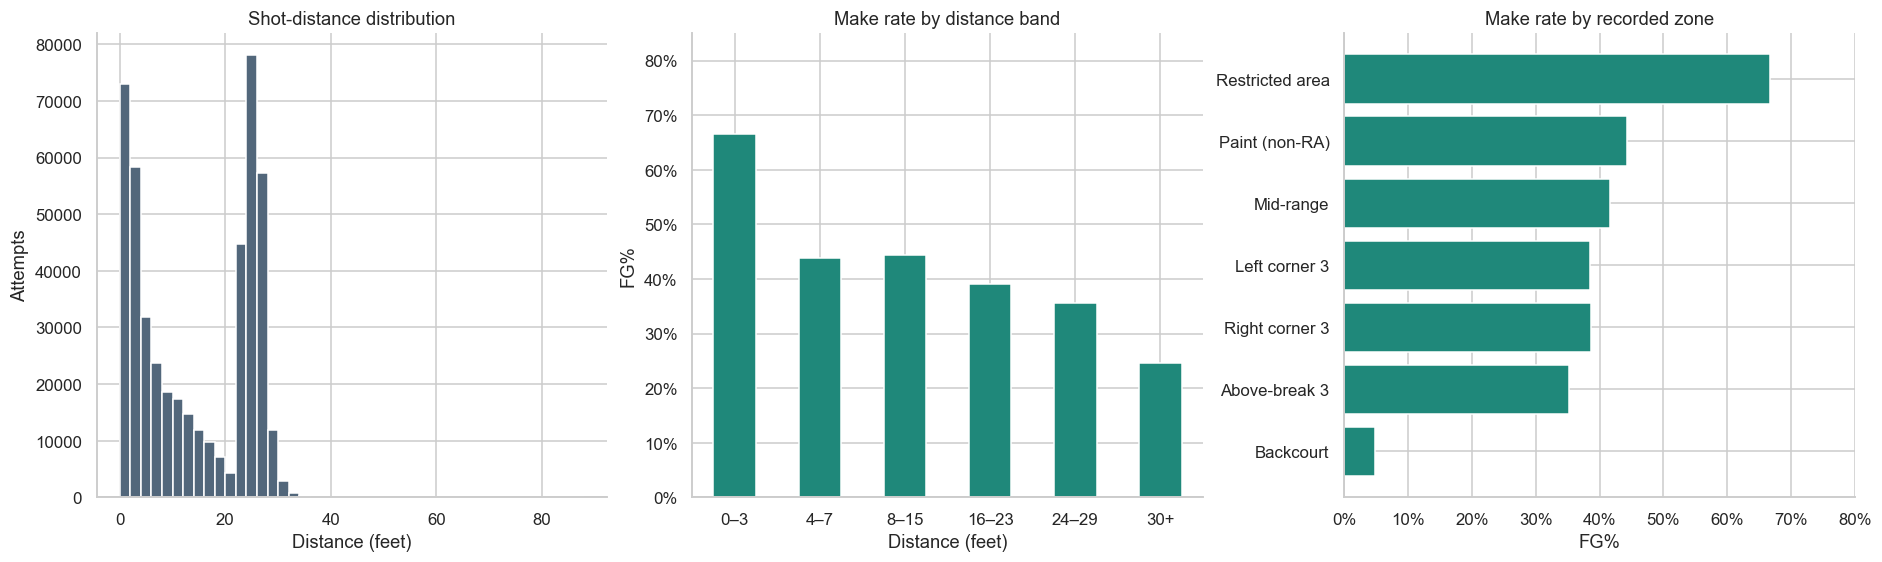

In [6]:
zone_order = ['Restricted Area', 'In The Paint (Non-RA)', 'Mid-Range', 'Left Corner 3',
              'Right Corner 3', 'Above the Break 3', 'Backcourt']
zone_summary = shot_summary(shots, ['shot_zone_basic']).reindex(zone_order)
distance_summary = shot_summary(shots, ['distance_band'])
display(zone_summary, distance_summary, shot_summary(shots, ['shot_type']))

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
axes[0].hist(shots['shot_distance'], bins=np.arange(0, 90, 2), color='#52677B')
axes[0].set(title='Shot-distance distribution', xlabel='Distance (feet)', ylabel='Attempts')
distance_summary['fg_pct'].plot.bar(ax=axes[1], color='#1F887A', rot=0)
axes[1].set(title='Make rate by distance band', xlabel='Distance (feet)', ylabel='FG%', ylim=(0, .85))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
short_labels = ['Restricted area', 'Paint (non-RA)', 'Mid-range', 'Left corner 3',
                'Right corner 3', 'Above-break 3', 'Backcourt']
axes[2].barh(short_labels, zone_summary['fg_pct'], color='#1F887A')
axes[2].invert_yaxis()
axes[2].set(title='Make rate by recorded zone', xlabel='FG%', xlim=(0, .8))
axes[2].xaxis.set_major_formatter(PercentFormatter(1))
save_show(fig, '02_distance_and_zones')

### Spatial patterns

The first map shows where attempts are concentrated. The second shows make rate in the same
2-foot bins, masking bins with fewer than 50 attempts. This prevents tiny samples from looking
like stable hotspots. The plotted window focuses on `x = −25…25` feet and `y = −5…41` feet;
shots outside it remain in every table and exported dataset. The black marker is `(0, 0)`.

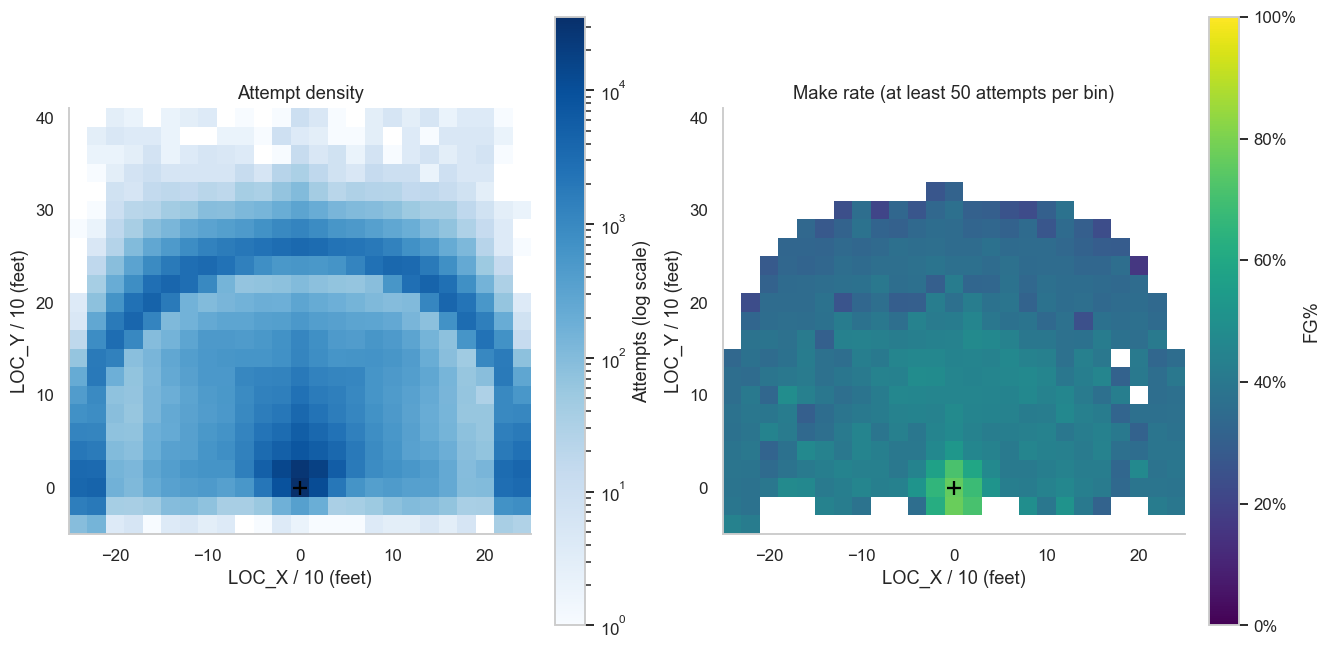

638 attempts outside the histogram bounds are retained in the data.


In [7]:
x_edges, y_edges = np.arange(-25, 27, 2), np.arange(-5, 43, 2)
attempt_grid, _, _ = np.histogram2d(shots['x_ft'], shots['y_ft'], bins=(x_edges, y_edges))
make_grid, _, _ = np.histogram2d(shots['x_ft'], shots['y_ft'], bins=(x_edges, y_edges),
                               weights=shots['shot_made_flag'].astype(float))
rate_grid = np.divide(make_grid, attempt_grid, out=np.full_like(make_grid, np.nan), where=attempt_grid>0)
rate_grid[attempt_grid < 50] = np.nan
fig, axes = plt.subplots(1, 2, figsize=(12, 7), constrained_layout=True)
volume = axes[0].pcolormesh(x_edges, y_edges, np.ma.masked_equal(attempt_grid.T, 0),
                           norm=LogNorm(vmin=1, vmax=attempt_grid.max()), cmap='Blues')
rate = axes[1].pcolormesh(x_edges, y_edges, rate_grid.T, vmin=0, vmax=1, cmap='viridis')
fig.colorbar(volume, ax=axes[0], label='Attempts (log scale)', shrink=.8)
fig.colorbar(rate, ax=axes[1], label='FG%', format=PercentFormatter(1), shrink=.8)
for ax, title in zip(axes, ['Attempt density', 'Make rate (at least 50 attempts per bin)']):
    ax.scatter([0], [0], marker='+', c='black', s=80)
    ax.set(title=title, xlabel='LOC_X / 10 (feet)', ylabel='LOC_Y / 10 (feet)',
           xlim=(-25, 25), ylim=(-5, 41), aspect='equal')
    ax.grid(False)
save_show(fig, '03_spatial_patterns')
in_window = shots['x_ft'].between(-25, 25) & shots['y_ft'].between(-5, 41)
print(f'{(~in_window).sum():,} attempts outside the histogram bounds are retained in the data.')

,attempts,makes,fg_pct
period_group,,,
Q1,120838,56890,0.471
Q2,117190,54560,0.466
Q3,116189,55137,0.475
Q4,110930,51279,0.462
OT,2390,1008,0.422


,attempts,makes,fg_pct
period_clock_band,,,
0–5 sec,10142,3269,0.322
6–24 sec,9051,4033,0.446
25–120 sec,64719,30382,0.469
121–360 sec,154078,72559,0.471
361–720 sec,229547,108631,0.473


attempts  makes  fg_pct
season_type    is_home is_late_fourth                         
Playoffs       0       0                  13700   6150   0.449
                       1                    618    272   0.440
               1       0                  13870   6387   0.460
                       1                    662    272   0.411
Regular season 0       0                 210270  98241   0.467
                       1                   9404   4148   0.441
               1       0                 209887  99182   0.473
                       1                   9126   4222   0.463

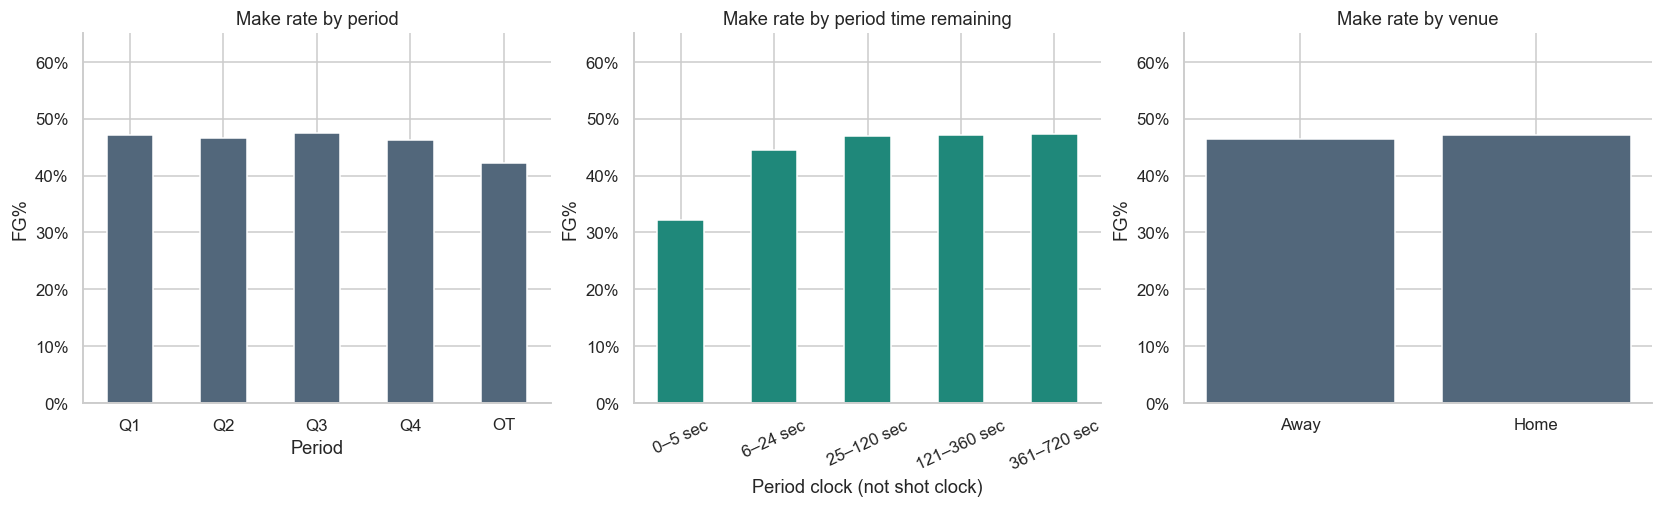

In [8]:
shots['period_group'] = np.where(shots['period'].le(4), 'Q' + shots['period'].astype(str), 'OT')
shots['period_clock_band'] = pd.cut(shots['seconds_remaining_period'],
    bins=[-1, 5, 24, 120, 360, 720], labels=['0–5 sec', '6–24 sec', '25–120 sec', '121–360 sec', '361–720 sec'])
period_summary = shot_summary(shots, ['period_group']).reindex(['Q1', 'Q2', 'Q3', 'Q4', 'OT'])
clock_summary = shot_summary(shots, ['period_clock_band'])
situation_summary = shot_summary(shots, ['season_type', 'is_home', 'is_late_fourth'])
display(period_summary, clock_summary, situation_summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
period_summary['fg_pct'].plot.bar(ax=axes[0], rot=0, color='#52677B')
axes[0].set(title='Make rate by period', xlabel='Period', ylabel='FG%')
clock_summary['fg_pct'].plot.bar(ax=axes[1], rot=25, color='#1F887A')
axes[1].set(title='Make rate by period time remaining', xlabel='Period clock (not shot clock)', ylabel='FG%')
home_summary = shot_summary(shots, ['is_home'])
axes[2].bar(['Away', 'Home'], home_summary.reindex([0, 1])['fg_pct'], color='#52677B')
axes[2].set(title='Make rate by venue', ylabel='FG%')
for ax in axes:
    ax.set_ylim(0, .65)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
save_show(fig, '04_game_situation')

### Coverage and category shifts

Compare shot mix across sources before assuming the two seasons are interchangeable. A change
in backcourt counts could reflect behavior, collection, or classification; these files do not
identify the cause. Keep the season indicator and consider a no-backcourt sensitivity analysis.

In [9]:
zone_by_source = shot_summary(shots, ['season', 'season_type', 'shot_zone_basic']).reset_index()
zone_by_source['attempt_share'] = zone_by_source['attempts'] / zone_by_source.groupby(
    ['season', 'season_type'])['attempts'].transform('sum')
display(zone_by_source.pivot(index='shot_zone_basic', columns=['season', 'season_type'], values='attempts'))
flag_sensitivity = shot_summary(shots, ['shot_type_zone_mismatch'])
display(flag_sensitivity)

season                 2024-25                 2025-26               
season_type           Playoffs Regular season Playoffs Regular season
shot_zone_basic                                                      
Above the Break 3         4272          68359     4262          67375
Backcourt                   68            517        5             29
In The Paint (Non-RA)     3002          44475     2842          43908
Left Corner 3              809          12188      814          12210
Mid-Range                 1741          21401     1677          22025
Restricted Area           3726          61190     4111          62253
Right Corner 3             759          11397      762          11360

,attempts,makes,fg_pct
shot_type_zone_mismatch,,,
False,467504,218862,0.468
True,33,12,0.364


## 5. Offensive skill and team defense

Historical features below only use **strictly earlier dates**. First aggregate makes and
attempts per entity/date, then subtract the current date from cumulative totals before joining
back to shots. Every shot for an entity on a date receives the same history, so no current-game
or same-day outcome can enter its features.

Offense uses player FG%, player-by-zone FG%, and three-point attempt share. Defense uses the
opposing team's FG% allowed overall and in the current zone. The denominator columns record
how much historical evidence supports each estimate.

We smooth FG% with **50 prior attempts**: `(prior makes + 50 × earlier league rate) /
(prior attempts + 50)`. Zone features use the earlier league rate in that zone. Only the first
date, when there is no earlier league evidence, falls back to a fixed 0.50. Historical
three-point share also uses 50 prior attempts with an earlier-league-share fallback (0.35 on
the first date). A zone with no earlier evidence falls back to the earlier overall league rate.
These are explicit starting assumptions, not tuned parameters.

History carries across the two seasons and follows player ID through trades. It weights older
games equally, so it does not rapidly capture roster or skill changes. Opponent FG% allowed
is confounded by shooter quality and shot mix, even within zones; it does not isolate defender
ability or constitute a possession-based defensive rating.

In [10]:
def prior_date_totals(frame, keys, prefix):
    # Return one history row per keys/date; never include outcomes on that date.
    daily = (frame.groupby(keys + ['game_date'], observed=True, dropna=False)
             .agg(attempts=('shot_made_flag', 'size'), makes=('shot_made_flag', 'sum'),
                  three_attempts=('is_three_pointer', 'sum')).reset_index()
             .sort_values(keys + ['game_date']))
    measures = ['attempts', 'makes', 'three_attempts']
    cumulative = daily.groupby(keys, observed=True, dropna=False)[measures].cumsum() if keys else daily[measures].cumsum()
    prior = cumulative - daily[measures]
    result = daily[keys + ['game_date']].copy()
    for measure in measures:
        result[f'{prefix}_prior_{measure}'] = prior[measure].astype('int64')
    result[f'{prefix}_history_through'] = (
        daily.groupby(keys, observed=True, dropna=False)['game_date'].shift(1)
        if keys else daily['game_date'].shift(1))
    return result

def add_history(frame, keys, prefix):
    history = prior_date_totals(frame, keys, prefix)
    merged = frame.merge(history, on=keys + ['game_date'], how='left', validate='many_to_one', sort=False)
    assert len(merged) == len(frame)
    cutoff = merged[f'{prefix}_history_through']
    assert (cutoff.isna() | cutoff.lt(merged['game_date'])).all()
    return merged

for keys, prefix in [([], 'league'), (['shot_zone_basic'], 'league_zone'),
                     (['player_id'], 'player'), (['player_id', 'shot_zone_basic'], 'player_zone'),
                     (['opponent_team_id'], 'opponent'),
                     (['opponent_team_id', 'shot_zone_basic'], 'opponent_zone')]:
    shots = add_history(shots, keys, prefix)

ALPHA = 50.0
league_fg = shots['league_prior_makes'].div(shots['league_prior_attempts'].replace(0, np.nan)).fillna(.5)
league_zone_fg = shots['league_zone_prior_makes'].div(
    shots['league_zone_prior_attempts'].replace(0, np.nan)).fillna(league_fg)
league_three_share = shots['league_prior_three_attempts'].div(
    shots['league_prior_attempts'].replace(0, np.nan)).fillna(.35)
for prefix, fallback in [('player', league_fg), ('player_zone', league_zone_fg),
                         ('opponent', league_fg), ('opponent_zone', league_zone_fg)]:
    shots[f'{prefix}_prior_fg_pct_smoothed'] = (
        shots[f'{prefix}_prior_makes'] + ALPHA * fallback) / (shots[f'{prefix}_prior_attempts'] + ALPHA)
    shots[f'{prefix}_has_history'] = shots[f'{prefix}_prior_attempts'].gt(0).astype('int8')
shots['player_prior_three_point_share'] = (
    shots['player_prior_three_attempts'] + ALPHA * league_three_share) / (shots['player_prior_attempts'] + ALPHA)

history_rates = ['player_prior_fg_pct_smoothed', 'player_zone_prior_fg_pct_smoothed',
                 'opponent_prior_fg_pct_smoothed', 'opponent_zone_prior_fg_pct_smoothed',
                 'player_prior_three_point_share']
assert shots[history_rates].notna().all().all()
assert shots[history_rates].ge(0).all().all() and shots[history_rates].le(1).all().all()
display(shots[['game_date', 'player_name', 'shot_zone_basic', 'opponent_abbr',
               'player_prior_attempts', 'player_zone_prior_attempts', *history_rates]].tail(5))

,game_date,player_name,shot_zone_basic,opponent_abbr,player_prior_attempts,player_zone_prior_attempts,player_prior_fg_pct_smoothed,player_zone_prior_fg_pct_smoothed,opponent_prior_fg_pct_smoothed,opponent_zone_prior_fg_pct_smoothed,player_prior_three_point_share
467532,2026-06-13,Josh Hart,Above the Break 3,SAS,1669,448,0.505,0.353,0.457,0.354,0.377
467533,2026-06-13,Dylan Harper,Restricted Area,NYK,870,406,0.505,0.648,0.463,0.654,0.287
467534,2026-06-13,Victor Wembanyama,Above the Break 3,NYK,2281,790,0.495,0.349,0.463,0.349,0.378
467535,2026-06-13,Stephon Castle,Restricted Area,NYK,2091,769,0.451,0.643,0.463,0.654,0.325
467536,2026-06-13,Victor Wembanyama,Above the Break 3,NYK,2281,790,0.495,0.349,0.463,0.349,0.378


In [11]:
# A small behavior check: changing today's labels must not change today's history.
toy = pd.DataFrame({'player_id': ['A', 'A', 'A', 'A'],
                    'game_date': pd.to_datetime(['2024-01-01', '2024-01-01', '2024-01-02', '2024-01-03']),
                    'shot_made_flag': [1, 0, 1, 0], 'is_three_pointer': [0, 1, 1, 0]})
before = prior_date_totals(toy, ['player_id'], 'player')
changed = toy.copy()
changed.loc[changed.game_date.eq(pd.Timestamp('2024-01-02')), 'shot_made_flag'] = 0
after = prior_date_totals(changed, ['player_id'], 'player')
pd.testing.assert_frame_equal(before[before.game_date.le('2024-01-02')], after[after.game_date.le('2024-01-02')])
assert before['player_prior_attempts'].tolist() == [0, 2, 3]
assert before['player_prior_makes'].tolist() == [0, 1, 2]
assert after['player_prior_makes'].tolist() == [0, 1, 1]

# Check actual totals against a direct earlier-date filter, independently of cumsum.
sample_row = shots.iloc[len(shots) // 2]
earlier = shots['game_date'].lt(sample_row['game_date'])
for keys, prefix in [(['player_id'], 'player'), (['player_id', 'shot_zone_basic'], 'player_zone'),
                     (['opponent_team_id'], 'opponent'), (['opponent_team_id', 'shot_zone_basic'], 'opponent_zone')]:
    mask = earlier.copy()
    for key in keys:
        mask &= shots[key].eq(sample_row[key])
    assert sample_row[f'{prefix}_prior_attempts'] == int(mask.sum())
    assert sample_row[f'{prefix}_prior_makes'] == int(shots.loc[mask, 'shot_made_flag'].sum())
print('History checks passed: no same-date labels; direct earlier-date totals match.')

History checks passed: no same-date labels; direct earlier-date totals match.


### Descriptive skill profiles

Full-sample player and opponent tables below are **EDA outputs only**. Player profiles include
shot mix; team profiles show percentages allowed within zones. Volume thresholds reduce unstable
displays, but these are not adjusted rankings of offensive or defensive talent.

,attempts,makes,fg_pct,player_name,three_point_attempt_share,mean_distance_ft
player_id,,,,,,
1628983,3766,1956,0.519,Shai Gilgeous-Alexander,0.240,12.475
1628973,3481,1647,0.473,Jalen Brunson,0.340,14.070
1630162,3321,1535,0.462,Anthony Edwards,0.457,15.707
1628378,3296,1520,0.461,Donovan Mitchell,0.452,15.622
1630595,3069,1414,0.461,Cade Cunningham,0.298,12.512
1627759,2999,1405,0.468,Jaylen Brown,0.289,13.025
203999,2885,1615,0.560,Nikola Jokić,0.254,11.307
1627750,2860,1345,0.470,Jamal Murray,0.384,15.480
1630178,2803,1267,0.452,Tyrese Maxey,0.411,14.436


,attempts,makes,fg_pct
opponent_abbr,,,
ATL,15239,7288,0.478
BKN,13858,6774,0.489
BOS,15981,7118,0.445
CHA,14501,6773,0.467
CHI,15478,7318,0.473
CLE,17061,7860,0.461
DAL,15216,7207,0.474
DEN,16886,7889,0.467
DET,15864,7147,0.451


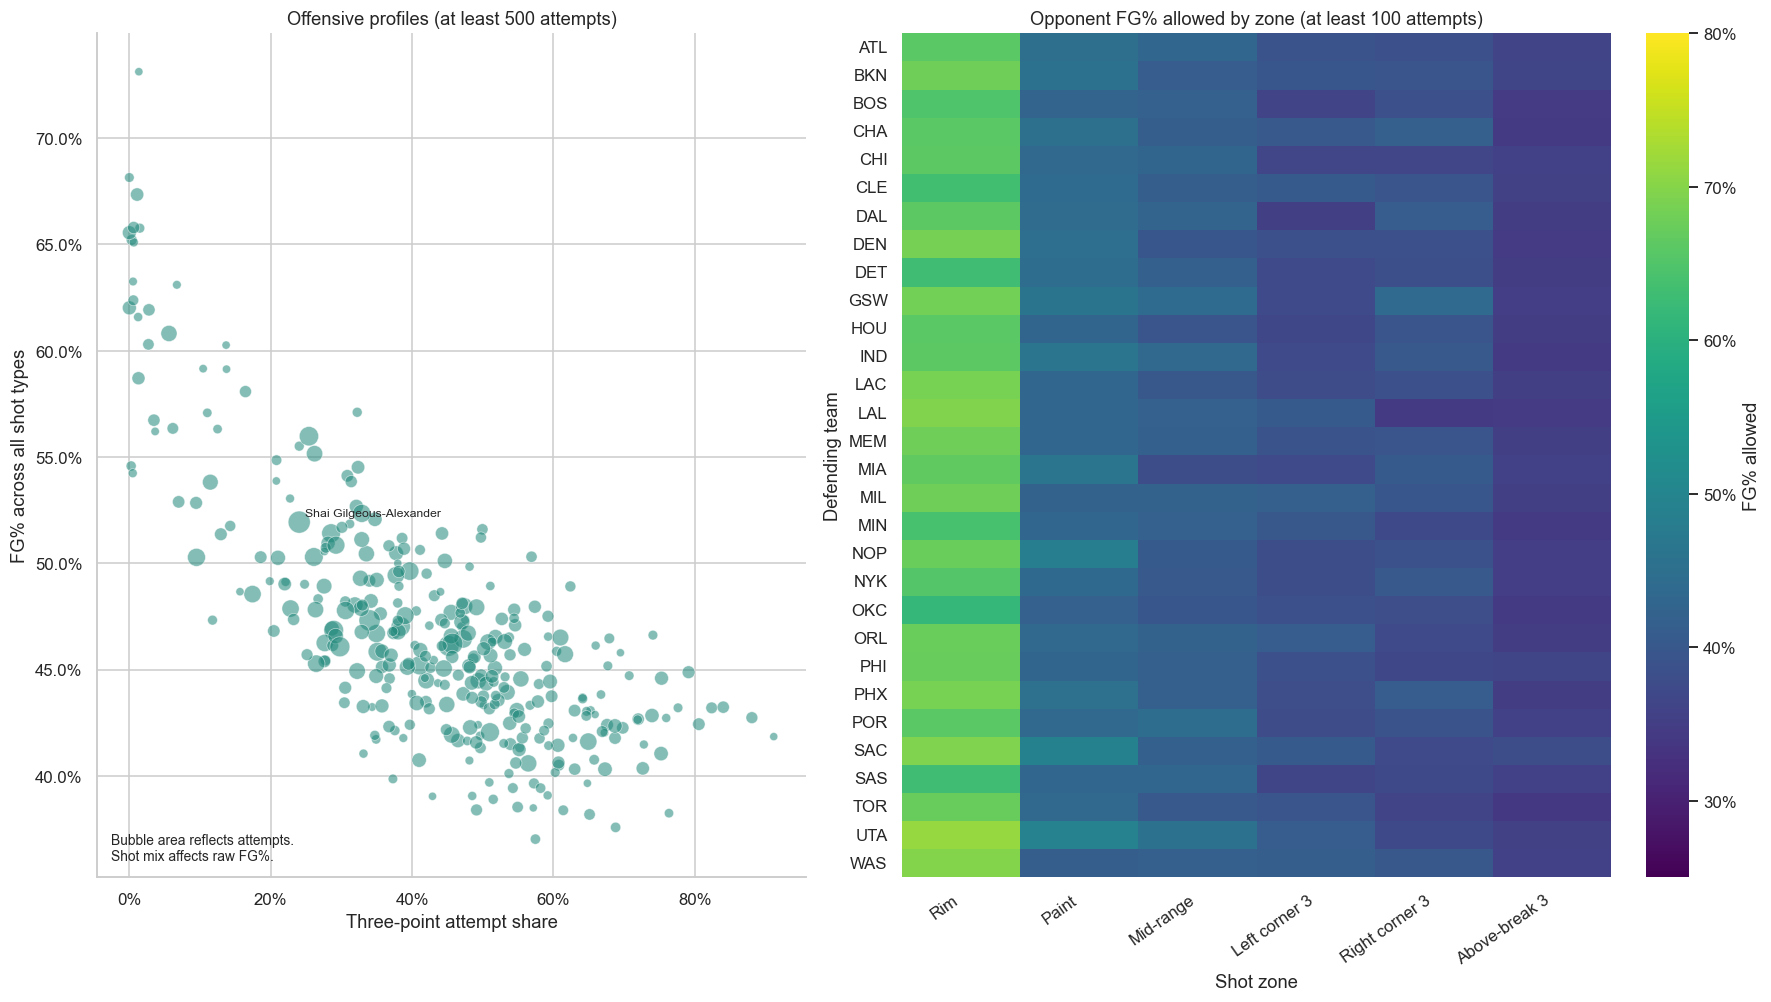

In [12]:
player_profiles = shot_summary(shots, ['player_id'])
player_profiles['player_name'] = player_profiles.index.map(display_names)
player_profiles['three_point_attempt_share'] = shots.groupby('player_id')['is_three_pointer'].mean()
player_profiles['mean_distance_ft'] = shots.groupby('player_id')['shot_distance'].mean()
player_zone_profiles = shot_summary(shots, ['player_id', 'shot_zone_basic'])
defense_profiles = shot_summary(shots, ['opponent_abbr'])
defense_zone_profiles = shot_summary(shots, ['opponent_abbr', 'shot_zone_basic'])
display(player_profiles.loc[player_profiles.attempts.ge(500)].sort_values('attempts', ascending=False).head(15))
display(defense_profiles.sort_index())

fig, axes = plt.subplots(1, 2, figsize=(16, 9), constrained_layout=True)
eligible = player_profiles.loc[player_profiles.attempts.ge(500)]
axes[0].scatter(eligible['three_point_attempt_share'], eligible['fg_pct'],
                s=eligible['attempts']/18, alpha=.55, c='#1F887A', edgecolors='white', linewidth=.5)
for _, row in eligible.nlargest(1, 'attempts').iterrows():
    axes[0].annotate(row['player_name'], (row['three_point_attempt_share'], row['fg_pct']),
                     xytext=(4, 4), textcoords='offset points', fontsize=8)
axes[0].set(title='Offensive profiles (at least 500 attempts)', xlabel='Three-point attempt share',
            ylabel='FG% across all shot types')
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].text(.02, .02, 'Bubble area reflects attempts.\nShot mix affects raw FG%.', transform=axes[0].transAxes, fontsize=9)
defense_matrix = defense_zone_profiles['fg_pct'].unstack('shot_zone_basic').reindex(columns=zone_order[:-1])
defense_counts = defense_zone_profiles['attempts'].unstack('shot_zone_basic').reindex(columns=zone_order[:-1])
sns.heatmap(defense_matrix.where(defense_counts.ge(100)).astype(float), ax=axes[1], cmap='viridis',
            vmin=.25, vmax=.8, cbar_kws={'label': 'FG% allowed', 'format': PercentFormatter(1)})
axes[1].set(title='Opponent FG% allowed by zone (at least 100 attempts)', xlabel='Shot zone', ylabel='Defending team')
axes[1].set_xticklabels(['Rim', 'Paint', 'Mid-range', 'Left corner 3', 'Right corner 3', 'Above-break 3'], rotation=35, ha='right')
save_show(fig, '05_offense_and_defense_profiles')

,history_quintile,attempts,makes,fg_pct,history_feature
0,1,52076,18054,0.347,player_zone
1,2,52076,19394,0.372,player_zone
2,3,52076,22413,0.430,player_zone
3,4,52073,30442,0.585,player_zone
4,5,52074,36320,0.697,player_zone
5,1,89525,31679,0.354,opponent_zone
6,2,89488,32820,0.367,opponent_zone
7,3,89531,37681,0.421,opponent_zone
8,4,89485,47704,0.533,opponent_zone
9,5,89496,60496,0.676,opponent_zone


**Interpretation:** these quintiles pool zones. Their gradients also reflect shot location and do not demonstrate extra predictive value from skill.

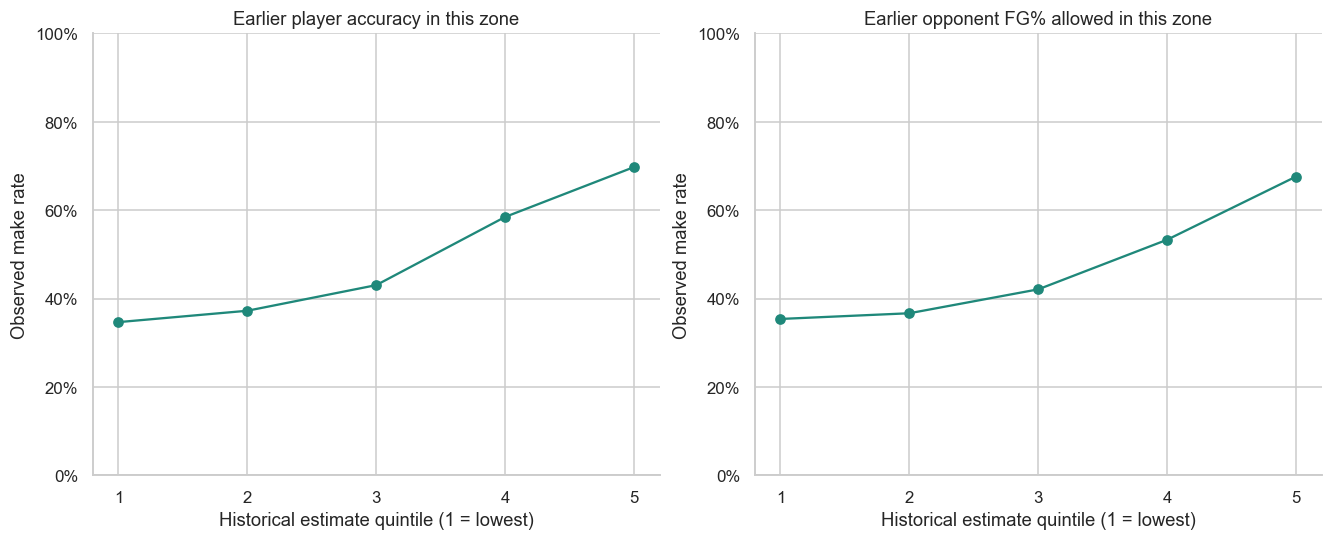

In [13]:
# Each attempt is binned by the historical estimate available BEFORE its game date.
# These pooled associations also reflect zone composition. They do not demonstrate
# incremental skill signal beyond location or held-out model performance.
history_associations = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, prefix, title in [(axes[0], 'player_zone', 'Earlier player accuracy in this zone'),
                          (axes[1], 'opponent_zone', 'Earlier opponent FG% allowed in this zone')]:
    eligible = shots.loc[shots[f'{prefix}_prior_attempts'].ge(100)].copy()
    eligible['history_quintile'] = pd.qcut(eligible[f'{prefix}_prior_fg_pct_smoothed'], 5,
                                          labels=False, duplicates='drop') + 1
    summary = shot_summary(eligible, ['history_quintile']).reset_index()
    summary['history_feature'] = prefix
    history_associations.append(summary)
    ax.plot(summary['history_quintile'], summary['fg_pct'], marker='o', color='#1F887A')
    ax.set(title=title, xlabel='Historical estimate quintile (1 = lowest)', ylabel='Observed make rate',
           xticks=summary['history_quintile'], ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
history_associations = pd.concat(history_associations, ignore_index=True)
display(history_associations)
display(Markdown('**Interpretation:** these quintiles pool zones. Their gradients also reflect '
                 'shot location and do not demonstrate extra predictive value from skill.'))
save_show(fig, '06_historical_skill_associations')

## 6. Prepare for later prediction work

The exports include a deliberately limited feature table and a 70% / 15% / 15% chronological
split of **unique game dates** (shot counts may differ). Games stay together. The full EDA above
has examined all dates, so this is a proposed research split, not an untouched holdout supporting
a final performance claim.

The historical features assume **daily updating**: a later validation/test date may use outcomes
from earlier validation/test dates, as would be available before that day's games. A fixed-origin
forecast would need history frozen at its training cutoff. Fit preprocessing and models only on
training rows, tune with validation, and evaluate once on test; never use random shot-level splits.

Suggested comparisons: (1) training prevalence, (2) location/distance/game situation, (3) add
offensive history, (4) add defensive history. Report log loss, Brier score, ROC AUC, and calibration,
with uncertainty resampled by game. Raw accuracy alone does not measure probability quality.

`event_type` directly reveals the target. `action_type` remains descriptive because recorded play
labels may depend on the completed action. Exclude them, full-sample profiles, target-derived
quality flags, names, IDs, provenance, and the label itself from predictors. Revisit action coding
only after confirming its availability at the chosen prediction time.

In [14]:
dates = np.sort(shots['game_date'].unique())
train_end = pd.Timestamp(dates[int(len(dates) * .70) - 1])
validation_end = pd.Timestamp(dates[int(len(dates) * .85) - 1])
shots['split'] = np.select([shots['game_date'].le(train_end), shots['game_date'].le(validation_end)],
                           ['train', 'validation'], default='test')
split_summary = (shots.groupby('split').agg(shots=('shot_made_flag', 'size'), games=('game_id', 'nunique'),
                 first_date=('game_date', 'min'), last_date=('game_date', 'max'),
                 fg_pct=('shot_made_flag', 'mean'), playoff_share=('is_playoffs', 'mean'))
                 .reindex(['train', 'validation', 'test']))
assert shots.groupby('game_id')['split'].nunique().eq(1).all()
assert split_summary.loc['train', 'last_date'] < split_summary.loc['validation', 'first_date']
assert split_summary.loc['validation', 'last_date'] < split_summary.loc['test', 'first_date']
display(split_summary)
display(pd.crosstab(shots['split'], [shots['season'], shots['season_type']]).reindex(['train', 'validation', 'test']))

context_numeric = ['shot_distance', 'x_ft', 'y_ft', 'period', 'seconds_remaining_period',
                   'is_home', 'is_overtime', 'is_playoffs', 'is_late_fourth', 'is_final_5_seconds_period']
context_categorical = ['shot_type', 'shot_zone_basic', 'shot_zone_area', 'season']
offense_features = ['player_prior_fg_pct_smoothed', 'player_zone_prior_fg_pct_smoothed',
                    'player_prior_three_point_share', 'player_prior_attempts', 'player_zone_prior_attempts',
                    'player_has_history', 'player_zone_has_history']
defense_features = ['opponent_prior_fg_pct_smoothed', 'opponent_zone_prior_fg_pct_smoothed',
                    'opponent_prior_attempts', 'opponent_zone_prior_attempts',
                    'opponent_has_history', 'opponent_zone_has_history']
feature_sets = {'location_and_situation': context_numeric + context_categorical,
                'plus_offense': context_numeric + context_categorical + offense_features,
                'plus_offense_and_defense': context_numeric + context_categorical + offense_features + defense_features}
features = feature_sets['plus_offense_and_defense']
identifiers = ['game_id', 'game_event_id', 'game_date', 'player_id', 'team_id', 'opponent_team_id', 'split']
model_ready = shots[identifiers + features + ['shot_made_flag']].copy()
assert len(features) == len(set(features))
assert not {'shot_made_flag', 'event_type', 'action_type', 'player_name'}.intersection(features)
assert not model_ready.duplicated(shot_key).any()
display(pd.DataFrame({'feature_set': feature_sets.keys(), 'predictors': [len(v) for v in feature_sets.values()]}))
display(model_ready[features].isna().sum().rename('missing_model_values').to_frame().T)

,shots,games,first_date,last_date,fg_pct,playoff_share
split,,,,,,
train,340288,1909,2024-10-22,2026-01-13,0.467,0.042
validation,85110,480,2026-01-14,2026-03-23,0.470,0.000
test,42139,240,2026-03-24,2026-06-13,0.471,0.343


season       2024-25                 2025-26               
season_type Playoffs Regular season Playoffs Regular season
split                                                      
train          14377         219527        0         106384
validation         0              0        0          85110
test               0              0    14473          27666

,feature_set,predictors
0,location_and_situation,14
1,plus_offense,21
2,plus_offense_and_defense,27


,shot_distance,x_ft,y_ft,period,seconds_remaining_period,is_home,is_overtime,is_playoffs,is_late_fourth,is_final_5_seconds_period,shot_type,shot_zone_basic,shot_zone_area,season,player_prior_fg_pct_smoothed,player_zone_prior_fg_pct_smoothed,player_prior_three_point_share,player_prior_attempts,player_zone_prior_attempts,player_has_history,player_zone_has_history,opponent_prior_fg_pct_smoothed,opponent_zone_prior_fg_pct_smoothed,opponent_prior_attempts,opponent_zone_prior_attempts,opponent_has_history,opponent_zone_has_history
missing_model_values,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 7. Export reusable data, audit tables, and findings

`nba_shots_clean.parquet` retains cleaned shot fields, provenance, review flags, and historical
features. The compressed CSV is a portable copy of the same table. Prefer Parquet because it
preserves ID, date, boolean, and category types. When reading the CSV, explicitly load IDs as
strings and parse `game_date`.

`nba_shots_model_ready.parquet` contains metadata, the approved predictors, split assignments,
and target. Select predictors using `feature_sets.json`; do not automatically use every column.
Reports include the input inventory, cleaning log, missingness, flagged records, profiles,
feature dictionary, and chronological split. The original archives are the source of truth.

In [15]:
feature_descriptions = {
    'shot_distance': 'Supplied integer distance in feet; retained without clipping.',
    'x_ft': 'LOC_X divided by 10; coordinate in feet.',
    'y_ft': 'LOC_Y divided by 10; coordinate in feet.',
    'period': 'Period number; values above 4 indicate overtime.',
    'seconds_remaining_period': 'Seconds left in the current period; not the shot clock.',
    'is_home': '1 if the shooter plays for the home team.',
    'is_overtime': '1 for periods above 4.',
    'is_playoffs': '1 for playoff archive records.',
    'is_late_fourth': '1 in Q4 with at most 120 seconds remaining; score margin unknown.',
    'is_final_5_seconds_period': '1 with at most 5 seconds left in any period.',
    'shot_type': 'Recorded two-point or three-point field goal.',
    'shot_zone_basic': 'Recorded broad shot zone; inconsistent records are flagged in the clean data.',
    'shot_zone_area': 'Recorded directional shot area.',
    'season': 'Season start/end label from source archive; categorical context.',
    'player_prior_fg_pct_smoothed': 'Player FG% before current date, smoothed toward earlier league FG%.',
    'player_zone_prior_fg_pct_smoothed': 'Player FG% in current zone before date, smoothed toward earlier zone FG%.',
    'player_prior_three_point_share': 'Earlier player three-point attempts / all attempts, smoothed toward earlier league share.',
    'opponent_prior_fg_pct_smoothed': 'Opponent FG% allowed before date, smoothed; team-level defensive proxy.',
    'opponent_zone_prior_fg_pct_smoothed': 'Opponent FG% allowed in this zone before date, smoothed; defensive proxy.',
}
for prefix in ['player', 'player_zone', 'opponent', 'opponent_zone']:
    feature_descriptions[f'{prefix}_prior_attempts'] = f'Attempts observed for {prefix} strictly before current date.'
    feature_descriptions[f'{prefix}_has_history'] = f'1 if {prefix} has at least one earlier-date attempt.'
assert set(feature_descriptions) == set(features)
feature_dictionary = pd.DataFrame([
    {'feature': feature, 'group': ('offense' if feature in offense_features else 'defense' if feature in defense_features else 'location/game situation'),
     'kind': 'categorical' if feature in context_categorical else 'numeric', 'description': feature_descriptions[feature]}
    for feature in features])

shots.to_parquet(DATA_DIR / 'nba_shots_clean.parquet', index=False)
shots.to_csv(DATA_DIR / 'nba_shots_clean.csv.gz', index=False, compression='gzip')
model_ready.to_parquet(DATA_DIR / 'nba_shots_model_ready.parquet', index=False)
tables = {'source_inventory': source_inventory, 'cleaning_log': cleaning_log,
          'data_quality_flags': quality_summary.reset_index(names='flag'),
          'missingness': missingness.reset_index(names='column'),
          'numeric_date_coercions': pd.Series(coercion_counts, name='coerced_to_missing').rename_axis('column').reset_index(),
          'player_name_variants': name_variants, 'quarantined_rows': quarantine,
          'flagged_shots': shots.loc[shots[quality_flags].any(axis=1)],
          'season_summary': coverage.reset_index(), 'zone_summary': zone_summary.reset_index(),
          'distance_summary': distance_summary.reset_index(), 'period_summary': period_summary.reset_index(),
          'period_clock_summary': clock_summary.reset_index(), 'situation_summary': situation_summary.reset_index(),
          'zone_by_source': zone_by_source, 'player_profiles': player_profiles.reset_index(),
          'player_zone_profiles': player_zone_profiles.reset_index(),
          'defense_profiles': defense_profiles.reset_index(), 'defense_zone_profiles': defense_zone_profiles.reset_index(),
          'history_associations': history_associations, 'split_summary': split_summary.reset_index(),
          'feature_dictionary': feature_dictionary}
for name, table in tables.items():
    table.to_csv(REPORT_DIR / f'{name}.csv', index=False)
(REPORT_DIR / 'feature_sets.json').write_text(json.dumps(feature_sets, indent=2))
manifest = {'source_files': source_inventory[['source_archive', 'sha256']].to_dict('records'),
            'clean_rows': len(shots), 'clean_columns': len(shots.columns),
            'target': 'shot_made_flag', 'history_policy': 'strictly earlier dates; expanding across seasons',
            'smoothing_prior_attempts': ALPHA, 'split_train_end': str(train_end.date()),
            'split_validation_end': str(validation_end.date()), 'package_versions': versions}
(REPORT_DIR / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2))

# Validate the saved artifact, including row count, shot identity, and target totals.
saved = pd.read_parquet(DATA_DIR / 'nba_shots_model_ready.parquet')
assert len(saved) == len(shots)
assert not saved.duplicated(shot_key).any()
assert int(saved.shot_made_flag.sum()) == int(shots.shot_made_flag.sum())
assert saved['game_id'].equals(model_ready['game_id'])
display(pd.DataFrame([{'file': str(path.relative_to(ROOT)), 'size_MB': path.stat().st_size / 1e6}
                      for path in sorted(DATA_DIR.iterdir())]))

,file,size_MB
0,data/processed/nba_shots_clean.csv.gz,34.962
1,data/processed/nba_shots_clean.parquet,27.040
2,data/processed/nba_shots_model_ready.parquet,12.667


In [16]:
two_three = shot_summary(shots, ['shot_type'])
backcourt = zone_by_source.loc[(zone_by_source.shot_zone_basic == 'Backcourt')
                               & (zone_by_source.season_type == 'Regular season')]
backcourt_text = ', '.join(f'{r.season}: {r.attempts:,}' for r in backcourt.itertuples())
display(Markdown(f'''
### Findings from these files

- **Coverage:** {len(shots):,} field-goal attempts, {shots.game_id.nunique():,} games,
  {shots.player_id.nunique():,} players, and {shots.team_id.nunique()} teams across 2024–25 and 2025–26.
- **Cleaning:** {duplicate_count:,} duplicate rows removed, {len(quarantine):,} rows quarantined,
  {int(shots.shot_type_zone_mismatch.sum()):,} shot-type/zone disagreements flagged and retained,
  and {len(name_variants)} player IDs with name variants reconciled for display.
- **Outcome:** overall FG% is {overall_fg:.2%}. Two-point FG% is
  {two_three.loc['2PT Field Goal', 'fg_pct']:.2%}; three-point FG% is
  {two_three.loc['3PT Field Goal', 'fg_pct']:.2%}.
- **Location matters descriptively:** restricted-area FG% is
  {zone_summary.loc['Restricted Area', 'fg_pct']:.2%}, versus
  {zone_summary.loc['Above the Break 3', 'fg_pct']:.2%} above the three-point break.
  Differences also reflect who shoots and how each shot is defended.
- **Distribution shift to investigate:** regular-season backcourt attempts are {backcourt_text}.
  Do not attribute this difference to a rule change, recording change, or strategy without more evidence.
- **Offense and defense:** earlier-date shooter and opponent-zone estimates are now available
  with their sample sizes. Team FG% allowed is only a defensive proxy; individual defense cannot
  be established from these files.

### Next research step

Fit the proposed chronological baseline comparisons and test whether historical offense and
defense improve probability predictions beyond location and game situation. This EDA does
**not** establish predictive performance. Evaluate sensitivity to flagged records, backcourt
attempts, competition type, smoothing strength, and recency of historical data.

To represent defense and offensive skill more directly, obtain pre-shot defender identity and
distance, lineup information, shot-clock time, pre-shot score margin, and possession context.
Join with validated game/event/player keys or a verified time alignment; timestamp every
feature so only information available before the shot is used.
'''))


### Findings from these files

- **Coverage:** 467,537 field-goal attempts, 2,629 games,
  684 players, and 30 teams across 2024–25 and 2025–26.
- **Cleaning:** 0 duplicate rows removed, 0 rows quarantined,
  33 shot-type/zone disagreements flagged and retained,
  and 3 player IDs with name variants reconciled for display.
- **Outcome:** overall FG% is 46.81%. Two-point FG% is
  54.61%; three-point FG% is
  35.94%.
- **Location matters descriptively:** restricted-area FG% is
  66.62%, versus
  35.14% above the three-point break.
  Differences also reflect who shoots and how each shot is defended.
- **Distribution shift to investigate:** regular-season backcourt attempts are 2024-25: 517, 2025-26: 29.
  Do not attribute this difference to a rule change, recording change, or strategy without more evidence.
- **Offense and defense:** earlier-date shooter and opponent-zone estimates are now available
  with their sample sizes. Team FG% allowed is only a defensive proxy; individual defense cannot
  be established from these files.

### Next research step

Fit the proposed chronological baseline comparisons and test whether historical offense and
defense improve probability predictions beyond location and game situation. This EDA does
**not** establish predictive performance. Evaluate sensitivity to flagged records, backcourt
attempts, competition type, smoothing strength, and recency of historical data.

To represent defense and offensive skill more directly, obtain pre-shot defender identity and
distance, lineup information, shot-clock time, pre-shot score margin, and possession context.
Join with validated game/event/player keys or a verified time alignment; timestamp every
feature so only information available before the shot is used.
